# Automated Model Evaluation and Quality Gates

## 1. Imports and settings

In [1]:
# %pip install "numpy<2" pandas "scikit-learn==1.4.2" xgboost joblib matplotlib

import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
MIN_RECALL = 0.70
MIN_PR_AUC = 0.20
MIN_ROC_AUC = 0.65
MIN_PRECISION = 0.15
STOP_ON_FAILURE = True

## 2. Load the saved files

The folder search works from the project root, the notebooks folder, or this notebook's folder. We use the threshold selected on validation data during training. We do not choose another threshold using the test set.

In [2]:
project_dir = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "notebooks/training/artifacts/evaluation.json").exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Open this notebook from inside the project folder.")

artifact_dir = project_dir / "notebooks/training/artifacts"
output_dir = project_dir / "notebooks/evaluation/results"
output_dir.mkdir(parents=True, exist_ok=True)

required_files = [
    "diabetes_processed.csv", "preprocessor.joblib", "xgboost-model",
    "evaluation.json", "transformed_feature_names.json",
]
for name in required_files:
    if not (artifact_dir / name).exists():
        raise FileNotFoundError(f"Missing {name}. Run the training notebook first.")

with open(artifact_dir / "evaluation.json") as f:
    training_report = json.load(f)
with open(artifact_dir / "transformed_feature_names.json") as f:
    saved_feature_names = json.load(f)

# Keep text categories exactly as they were saved.
df = pd.read_csv(artifact_dir / "diabetes_processed.csv", keep_default_na=False)
feature_cols = training_report["raw_model_features"]
decision_threshold = float(training_report["decision_threshold"])
if not np.isfinite(decision_threshold) or not 0 <= decision_threshold <= 1:
    raise ValueError("The saved decision threshold must be between 0 and 1.")

print("Dataset shape:", df.shape)
print("Saved threshold:", round(decision_threshold, 4))

Dataset shape: (101766, 57)
Saved threshold: 0.4349


## 3. Check the data

Missing columns, repeated encounters, or invalid labels should stop evaluation instead of producing a misleading result.

In [3]:
required_cols = feature_cols + ["encounter_id", "patient_nbr", "readmitted_30d"]
missing_cols = sorted(set(required_cols) - set(df.columns))
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")
if df.empty or df[required_cols].isna().any().any() or df[required_cols].eq("").any().any():
    raise ValueError("The evaluation data is empty or contains missing values.")
if df["encounter_id"].duplicated().any():
    raise ValueError("Duplicate encounter IDs were found.")
if set(df["readmitted_30d"].unique()) != {0, 1}:
    raise ValueError("The target must contain both classes: 0 and 1.")

print("Data checks: PASS")

Data checks: PASS


## 4. Recreate the patient-level split

This is the same 70/15/15 split used in training. A patient's encounters must stay in one split so the test results do not benefit from seeing the same patient during training.

In [4]:
patient_ids = df["patient_nbr"].astype(str)
y = df["readmitted_30d"]
patient_table = (
    pd.DataFrame({"patient_nbr": patient_ids, "target": y})
    .groupby("patient_nbr", as_index=False)["target"].max()
)
train_patients, temp_patients = train_test_split(
    patient_table, test_size=0.30, random_state=RANDOM_STATE,
    stratify=patient_table["target"],
)
validation_patients, test_patients = train_test_split(
    temp_patients, test_size=0.50, random_state=RANDOM_STATE,
    stratify=temp_patients["target"],
)
train_ids = set(train_patients["patient_nbr"])
validation_ids = set(validation_patients["patient_nbr"])
test_ids = set(test_patients["patient_nbr"])

no_patient_overlap = (
    train_ids.isdisjoint(validation_ids)
    and train_ids.isdisjoint(test_ids)
    and validation_ids.isdisjoint(test_ids)
)
if not no_patient_overlap:
    raise ValueError("A patient appears in more than one split.")

train_mask = patient_ids.isin(train_ids)
test_mask = patient_ids.isin(test_ids)
X_test = df.loc[test_mask, feature_cols].copy()
y_test = y.loc[test_mask].copy()
if set(y_test.unique()) != {0, 1}:
    raise ValueError("The test set needs both classes to calculate ROC-AUC.")

print("Test encounters:", len(y_test))
print("Test readmission rate:", round(y_test.mean(), 4))
print("Patient overlap check: PASS")

Test encounters: 15278
Test readmission rate: 0.1102
Patient overlap check: PASS


## 5. Make predictions with the saved model

Only transform the test data. Fitting the preprocessor again would change the model inputs.

In [5]:
preprocessor = joblib.load(artifact_dir / "preprocessor.joblib")
if list(preprocessor.feature_names_in_) != feature_cols:
    raise ValueError("The raw feature order does not match the preprocessor.")
if preprocessor.get_feature_names_out().tolist() != saved_feature_names:
    raise ValueError("The transformed feature names do not match the saved list.")

X_test_t = preprocessor.transform(X_test)
model = xgb.Booster()
model.load_model(artifact_dir / "xgboost-model")
if X_test_t.shape[1] != model.num_features():
    raise ValueError("The preprocessor and model have different feature counts.")

test_prob = model.predict(xgb.DMatrix(X_test_t))
if test_prob.shape != (len(y_test),):
    raise ValueError("Expected one probability for each test encounter.")
if not np.isfinite(test_prob).all() or ((test_prob < 0) | (test_prob > 1)).any():
    raise ValueError("Predictions must be finite probabilities between 0 and 1.")
test_pred = (test_prob >= decision_threshold).astype(int)
print("Predictions created:", len(test_pred))

/opt/conda/lib/python3.12/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.4.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/conda/lib/python3.12/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.4.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/conda/lib/python3.12/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator ColumnTransformer from version 1.4.2 when using version 1.7.2. This might lead to breaking code o

Predictions created: 15278


## 6. Calculate metrics and compare with a benchmark

The majority-class benchmark always predicts the most common training class, like `00-models.ipynb`. Accuracy is included for comparison, but it is not a quality gate because most encounters are not readmitted within 30 days.

In [6]:
def calculate_metrics(y_true, probabilities, predictions):
    return {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "pr_auc": float(average_precision_score(y_true, probabilities)),
        "roc_auc": float(roc_auc_score(y_true, probabilities)),
        "recall": float(recall_score(y_true, predictions, zero_division=0)),
        "precision": float(precision_score(y_true, predictions, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, zero_division=0)),
    }

majority_class = int(y.loc[train_mask].mode().iloc[0])
benchmark_pred = np.full(len(y_test), majority_class)
benchmark_prob = benchmark_pred.astype(float)
benchmark_metrics = calculate_metrics(y_test, benchmark_prob, benchmark_pred)
test_metrics = calculate_metrics(y_test, test_prob, test_pred)

comparison = pd.DataFrame(
    [benchmark_metrics, test_metrics], index=["Majority class", "XGBoost"]
)
print(comparison.round(4))

# This helps spot a mismatch with the original training artifacts.
original_metrics = pd.Series(training_report["test_metrics"]).drop("threshold")
recheck = pd.DataFrame({"saved": original_metrics, "current": pd.Series(test_metrics)})
recheck["difference"] = recheck["current"] - recheck["saved"]
print("\nComparison with the saved evaluation:")
print(recheck.loc[original_metrics.index].round(6))

                accuracy  pr_auc  roc_auc  recall  precision      f1
Majority class    0.8898  0.1102   0.5000  0.0000     0.0000  0.0000
XGBoost           0.5546  0.2287   0.6836  0.7251     0.1614  0.2641

Comparison with the saved evaluation:
              saved   current  difference
pr_auc     0.228735  0.228735         0.0
roc_auc    0.683650  0.683650         0.0
recall     0.725059  0.725059         0.0
precision  0.161444  0.161444         0.0
f1         0.264086  0.264086         0.0


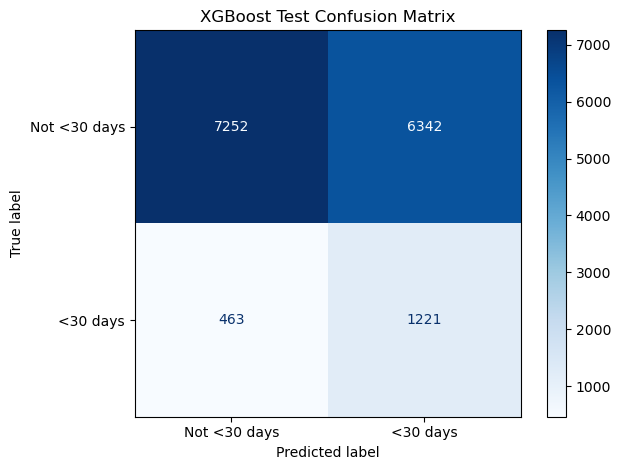

In [7]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Not <30 days", "<30 days"], cmap="Blues"
)
plt.title("XGBoost Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Apply the quality gates

All checks must pass. We require minimum recall, PR-AUC, ROC-AUC, and precision, plus better recall and PR-AUC than the majority-class benchmark. A failed check means the model needs review before the next deployment step.

In [8]:
gate_results = pd.DataFrame([
    {"check": "Recall", "actual": test_metrics["recall"],
     "rule": f">= {MIN_RECALL}", "passed": test_metrics["recall"] >= MIN_RECALL},
    {"check": "PR-AUC", "actual": test_metrics["pr_auc"],
     "rule": f">= {MIN_PR_AUC}", "passed": test_metrics["pr_auc"] >= MIN_PR_AUC},
    {"check": "ROC-AUC", "actual": test_metrics["roc_auc"],
     "rule": f">= {MIN_ROC_AUC}", "passed": test_metrics["roc_auc"] >= MIN_ROC_AUC},
    {"check": "Precision", "actual": test_metrics["precision"],
     "rule": f">= {MIN_PRECISION}", "passed": test_metrics["precision"] >= MIN_PRECISION},
    {"check": "Beat benchmark PR-AUC", "actual": test_metrics["pr_auc"],
     "rule": f"> {benchmark_metrics['pr_auc']:.4f}",
     "passed": test_metrics["pr_auc"] > benchmark_metrics["pr_auc"]},
    {"check": "Beat benchmark recall", "actual": test_metrics["recall"],
     "rule": f"> {benchmark_metrics['recall']:.4f}",
     "passed": test_metrics["recall"] > benchmark_metrics["recall"]},
])
all_passed = bool(gate_results["passed"].all())
status = "PASS" if all_passed else "FAIL"
print(gate_results.to_string(index=False))
print("\nOverall quality gate:", status)

                check   actual     rule  passed
               Recall 0.725059   >= 0.7    True
               PR-AUC 0.228735   >= 0.2    True
              ROC-AUC 0.683650  >= 0.65    True
            Precision 0.161444  >= 0.15    True
Beat benchmark PR-AUC 0.228735 > 0.1102    True
Beat benchmark recall 0.725059 > 0.0000    True

Overall quality gate: PASS


## 8. Save results and stop if a gate fails

The JSON report and CSV table are saved before raising an error, so failed checks can still be reviewed. `STOP_ON_FAILURE = True` makes an automated notebook run stop with an error when any gate fails.

This notebook does not register or deploy a model. Run it before deployment and proceed only after it passes. The training notebook also saves bias results for race, age, and gender; review those separately because these overall metric gates do not establish fairness.

In [9]:
quality_report = {
    "model": training_report["model"],
    "status": status,
    "test_encounters": len(y_test),
    "random_state": RANDOM_STATE,
    "decision_threshold": decision_threshold,
    "patient_overlap_check": no_patient_overlap,
    "test_metrics": test_metrics,
    "benchmark_metrics": benchmark_metrics,
    "confusion_matrix": confusion_matrix(y_test, test_pred, labels=[0, 1]).tolist(),
    "quality_gates": gate_results.to_dict(orient="records"),
}
with open(output_dir / "quality_gate_report.json", "w") as f:
    json.dump(quality_report, f, indent=2, allow_nan=False)
gate_results.to_csv(output_dir / "quality_gates.csv", index=False)
comparison.to_csv(output_dir / "model_comparison.csv", index_label="model")

print("Reports saved to:", output_dir)
if not all_passed and STOP_ON_FAILURE:
    failed_checks = gate_results.loc[~gate_results["passed"], "check"].tolist()
    raise RuntimeError(f"Quality gate FAILED: {failed_checks}")
print("Quality gate result:", status)

Reports saved to: /home/sagemaker-user/diabetes-readmission-prediction/notebooks/evaluation/results
Quality gate result: PASS
